In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# QUESTION 1
# Probability of losing 5 red bets in a row
# ============================================================

rng = np.random.default_rng(42)

n = 5
num_trials = 500_000


# European roulette red numbers
red_numbers = np.array([
    1, 3, 5, 7, 9,
    12, 14, 16, 18,
    19, 21, 23, 25, 27,
    30, 32, 34, 36
])


# ============================================================
# Theoretical probability
# ============================================================

p_loss = 19 / 37

theoretical_probability = (
    p_loss ** n
)


# ============================================================
# Monte Carlo simulation
#
# Each row represents one experiment of 5 spins.
# ============================================================

spins = rng.integers(
    0,
    37,
    size=(num_trials, n)
)


# Determine whether each spin landed on red
is_red = np.isin(
    spins,
    red_numbers
)


# A red bet loses whenever the spin is not red
is_loss = ~is_red


# Determine whether all 5 spins were losses
lost_all_five = np.all(
    is_loss,
    axis=1
)


# Monte Carlo probability
simulated_probability = np.mean(
    lost_all_five
)


# ============================================================
# Statistical verification
# ============================================================

standard_error = np.sqrt(
    theoretical_probability
    *
    (1 - theoretical_probability)
    /
    num_trials
)

difference = (
    simulated_probability
    -
    theoretical_probability
)

z_score = (
    difference
    /
    standard_error
)


print("QUESTION 1")
print("-----------------------------------")

print(
    "Theoretical probability =",
    theoretical_probability
)

print(
    "Theoretical percentage =",
    100 * theoretical_probability,
    "%"
)

print(
    "Simulated probability =",
    simulated_probability
)

print(
    "Simulated percentage =",
    100 * simulated_probability,
    "%"
)

print(
    "Difference =",
    difference
)

print(
    "Monte Carlo standard error =",
    standard_error
)

print(
    "Difference in standard errors =",
    z_score
)


# ============================================================
# Automated verification
# ============================================================

if abs(difference) < 4 * standard_error:

    print()
    print(
        "PASS: Simulation agrees with theory "
        "within 4 Monte Carlo standard errors."
    )

else:

    print()
    print(
        "WARNING: Simulation differs from theory "
        "more than expected."
    )

QUESTION 1
-----------------------------------
Theoretical probability = 0.0357074950308936
Theoretical percentage = 3.5707495030893597 %
Simulated probability = 0.035462
Simulated percentage = 3.5462000000000002 %
Difference = -0.00024549503089359853
Monte Carlo standard error = 0.0002624213018392841
Difference in standard errors = -0.9354996304528214

PASS: Simulation agrees with theory within 4 Monte Carlo standard errors.


QUESTION 2
-----------------------------------
Expected profit for one spin = -0.027027027027026973
Theoretical expected profit after 100 spins = -2.7027027027026973
Theoretical expected loss = 2.7027027027026973

Simulated mean profit = -2.67761
Theoretical variance = 99.92695398100804
Simulated variance = 99.68430468789998
Theoretical standard deviation = 9.996347031841584
Simulated standard deviation = 9.984202756750285

Difference between simulated and theoretical mean = 0.025092702702697256
Monte Carlo standard error of mean = 0.022352511489876038
Difference in standard errors = 1.1225898581491531

PASS: Simulated mean agrees with theory within 4 Monte Carlo standard errors.


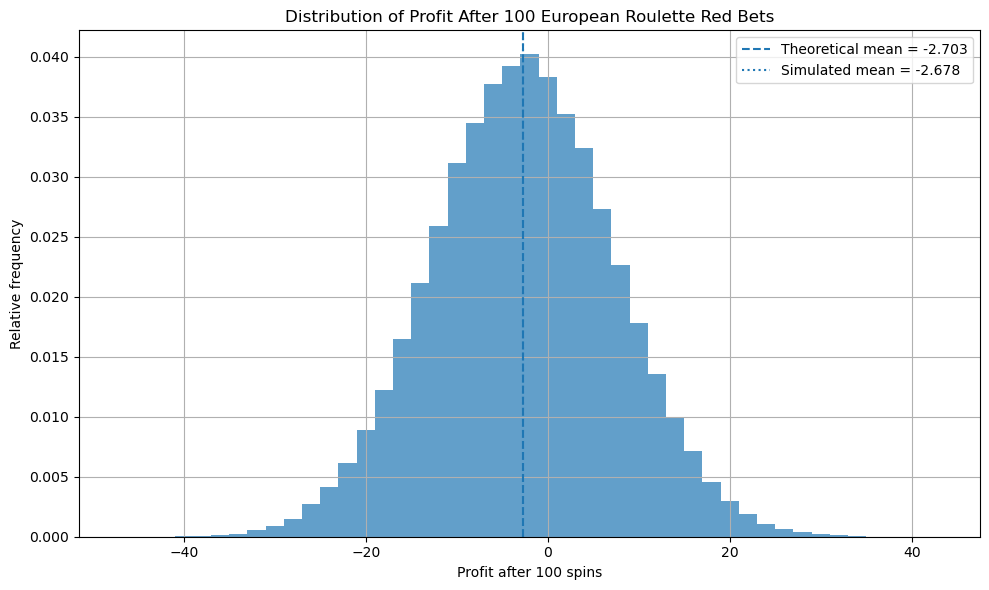

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# QUESTION 2
# Expected profit after 100 one-unit red bets
# ============================================================

rng = np.random.default_rng(42)

N = 100

num_sessions = 200_000

p_win = 18 / 37
p_loss = 19 / 37


# ============================================================
# Theoretical expectation
# ============================================================

expected_profit_one_spin = (
    p_win
    -
    p_loss
)

theoretical_mean = (
    N
    *
    expected_profit_one_spin
)


# ============================================================
# Theoretical variance
# ============================================================

variance_one_spin = (
    1
    -
    expected_profit_one_spin**2
)

theoretical_variance = (
    N
    *
    variance_one_spin
)

theoretical_sd = np.sqrt(
    theoretical_variance
)


# ============================================================
# Monte Carlo simulation
#
# Number of red wins in each 100-spin session
# ============================================================

wins = rng.binomial(
    N,
    p_win,
    size=num_sessions
)


# If there are W wins:
#
# profit = W - (N-W)
#        = 2W - N
#
profits = (
    2 * wins
    -
    N
)


# ============================================================
# Simulation statistics
# ============================================================

simulated_mean = np.mean(
    profits
)

simulated_variance = np.var(
    profits
)

simulated_sd = np.std(
    profits
)


# Standard error of Monte Carlo estimate of mean
standard_error_mean = (
    theoretical_sd
    /
    np.sqrt(num_sessions)
)

difference = (
    simulated_mean
    -
    theoretical_mean
)

z_score = (
    difference
    /
    standard_error_mean
)


print("QUESTION 2")
print("-----------------------------------")

print(
    "Expected profit for one spin =",
    expected_profit_one_spin
)

print(
    "Theoretical expected profit after",
    N,
    "spins =",
    theoretical_mean
)

print(
    "Theoretical expected loss =",
    -theoretical_mean
)

print()

print(
    "Simulated mean profit =",
    simulated_mean
)

print(
    "Theoretical variance =",
    theoretical_variance
)

print(
    "Simulated variance =",
    simulated_variance
)

print(
    "Theoretical standard deviation =",
    theoretical_sd
)

print(
    "Simulated standard deviation =",
    simulated_sd
)

print()

print(
    "Difference between simulated "
    "and theoretical mean =",
    difference
)

print(
    "Monte Carlo standard error of mean =",
    standard_error_mean
)

print(
    "Difference in standard errors =",
    z_score
)


# ============================================================
# Automated verification
# ============================================================

if abs(difference) < 4 * standard_error_mean:

    print()
    print(
        "PASS: Simulated mean agrees with theory "
        "within 4 Monte Carlo standard errors."
    )

else:

    print()
    print(
        "WARNING: Simulation differs from theory "
        "more than expected."
    )


# ============================================================
# Plot distribution of total profit
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    profits,
    bins=np.arange(
        profits.min() - 1,
        profits.max() + 3,
        2
    ),
    density=True,
    alpha=0.7
)

plt.axvline(
    theoretical_mean,
    linestyle="--",
    label=(
        "Theoretical mean = "
        f"{theoretical_mean:.3f}"
    )
)

plt.axvline(
    simulated_mean,
    linestyle=":",
    label=(
        "Simulated mean = "
        f"{simulated_mean:.3f}"
    )
)

plt.xlabel(
    "Profit after 100 spins"
)

plt.ylabel(
    "Relative frequency"
)

plt.title(
    "Distribution of Profit After "
    "100 European Roulette Red Bets"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "roulette_100_spin_profit_simulation.png",
    dpi=300
)

plt.show()